In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F


""" In this code, we perform a number of experiments to see how much of training data is needed
to resonably train a LeNet5 model, if we use only a small fraction of the training samples, how would the validation and test accuracy change,
we can try these experients with different increments i.e., 1% of training data, 2%, and so on until 10%.
We can plot these results with x-axis representing %age of trainin data y-axis representing validation and test accuracy
I reuse the code from LeNet-5_MNIST_L2_Regularization_EarlyStopping_Augmentation.ipynb and modify it to fit the requirements.
 """


# Hardcoded for simplicity
percentage_of_traning_data = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
num_of_experiments = len(percentage_of_traning_data)


class LeNet5(nn.Module):
    def __init__(self, num_of_classes, p): # 'p' probability of an element being zeroed out
        # Initialize the parent class (nn.Module)
        super(LeNet5, self).__init__()

        # Layer 1: Convolutional + BatchNorm2D  +  Pooling
        ''' we are using three channels as input (instead of 1) for some experiments that will be done later '''
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=6, kernel_size=5, stride=1, padding=2)  # 28x28 -> 28x28
        self.bn1 = nn.BatchNorm2d(6)
        self.pool1 = nn.AvgPool2d(kernel_size=2, stride=2)  # 28x28 -> 14x14
        # Layer 2: Convolutional + BatchNorm2D + Pooling
        self.conv2 = nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5, stride=1)  # 14x14 -> 10x10
        self.bn2 = nn.BatchNorm2d(16)
        self.pool2 = nn.AvgPool2d(kernel_size=2, stride=2)  # 10x10 -> 5x5
        # Layer 3: Fully Connected + BatchNorm1D
        self.fc1 = nn.Linear(in_features=16*5*5, out_features=120)
        self.bn3 = nn.BatchNorm1d(120)
        # Layer 4: Fully Connected + BatchNorm1D
        self.fc2 = nn.Linear(in_features=120, out_features=84)
        self.bn4 = nn.BatchNorm1d(84)
        # Layer 5: Output Layer
        self.fc3 = nn.Linear(in_features=84, out_features=num_of_classes)
        # Dropout layers
        self.dropout = nn.Dropout(p)  # dropout layer defined in __init__

    def forward(self, x):
        # Layer 1: Conv2 -> BatchNorm -> Pooling -> Activation
        x = F.relu(self.pool1(self.bn1(self.conv1(x))))

        # Layer 2: Conv2 -> BatchNorm -> Pooling -> Activation
        x = F.relu(self.pool2(self.bn2(self.conv2(x))))

        # Flatten the output from the convolutional layers
        x = x.view(-1, 16 * 5 * 5)
        # Layer 3: Fully Connected + BatchNorm + Activation
        x = F.relu(self.bn3(self.fc1(x)))
        # Apply dropout after first FC layer
        x = self.dropout(x)
        # Layer 4: Fully Connected +  BatchNorm + Activation
        x = F.relu(self.bn4(self.fc2(x)))
        # Apply dropout after second FC layer
        x = self.dropout(x)
        # Layer 5: Fully Connected (Output)
        x = self.fc3(x)
        return x

# Creating a model object/instance
model = LeNet5(num_of_classes=10, p = 0.5)
print(model)

LeNet5(
  (conv1): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (bn1): BatchNorm2d(6, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool1): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (bn2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool2): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (bn3): BatchNorm1d(120, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (bn4): BatchNorm1d(84, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
)


In [ ]:
import torch.optim as optim

'''  Decide if the calculations are perfomed by GPU or CPU  '''
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
'''.to(device): moves tensors and models to the specified device (either GPU or CPU).
This ensures that all computations happen on the same device, avoiding errors or inefficiencies.'''
model = model.to(device)
# Cross Entropy Loss for multi-class classification
criterion = nn.CrossEntropyLoss()
''' L2 Regularization adds a penalty proportional to the square of the magnitude
 of the weights to the loss function. Discourages the model from assigning
  too much importance to any individual feature by keeping the weights small.
 The larger the weight, the higher the penalty.'''
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=0.0005)  # L2 regularization via weight_decay


In [ ]:
class EarlyStopping:
    """
    Initializes the early stopping mechanism.

    Args:
        patience (int): Number of epochs to wait for improvement.
        delta (float): Minimum change in validation loss to qualify as improvement.

    """
    def __init__(self, patience, delta):
        self.patience = patience
        self.delta = delta
        self.best_score = None  # Tracks the best loss (lower is better)
        self.early_stop = False  # Flag for early stopping
        self.counter = 0  # Counter for epochs without improvement
        self.best_loss = np.inf  # Best loss starts as infinity

    ''' special method that allows us to use the object as if it were a function. '''
    def __call__(self, val_loss, model):
        """
        Training should be stopped early based on validation loss.

        Args:
            val_loss (float): Current epoch's validation loss.
            model (torch.nn.Module): Model to save if validation loss improves.
        """
        score = -val_loss  # Loss is used as the score (lower is better, so we negate it)

        # If this is the first epoch or loss improved significantly
        if self.best_score is None:
            self.best_score = score
            self.save_checkpoint(val_loss, model)
        elif score < self.best_score - self.delta:
            # No significant improvement (i..e, loss hasn't decreased enough)
            self.counter += 1
            print(f'EarlyStopping counter: {self.counter} out of {self.patience}')
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            # Improvement in loss
            self.best_score = score
            self.save_checkpoint(val_loss, model)
            self.counter = 0  # Reset the counter if loss improves

    def save_checkpoint(self, val_loss, model):
        """
        Save the model when validation loss improves.

        Args:
            val_loss (float): Current epoch's validation loss.
            model (torch.nn.Module): Model to save if validation loss improves.
        """
        if val_loss < self.best_loss:  # We save if loss decreased
            self.best_loss = val_loss
            checkpoint_name = "checkpoint.pth"
            torch.save(model.state_dict(), checkpoint_name)
            print(f'Model saved as {checkpoint_name}')

In [ ]:
## A method to train the model and return train and validation metrics
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs, device):
  early_stopping = EarlyStopping(patience=5, delta=0.0001)

  train_loss = None
  val_loss = None
  train_accuracy = None
  val_accuracy = None
  epoch = 0
  # Initialize lists to store training and validation metrics


  for epoch in range(num_epochs):
      model.train()
      running_loss = 0.0
      correct = 0
      total = 0
      for inputs, labels in train_loader:
          inputs, labels = inputs.to(device), labels.to(device)
          optimizer.zero_grad()
          outputs = model(inputs)
          loss = criterion(outputs, labels)
          loss.backward()
          optimizer.step()
          running_loss += loss.item()
          _, predicted = torch.max(outputs, 1)
          total += labels.size(0)
          correct += (predicted == labels).sum().item()
      train_loss = running_loss / len(train_loader)
      train_accuracy = 100 * correct / total

      # .eval indicates that the model is used for prediction.
      model.eval()
      val_loss = 0.0
      correct = 0
      total = 0
      with torch.no_grad():
          for inputs, labels in val_loader:
              inputs, labels = inputs.to(device), labels.to(device)
              outputs = model(inputs)
              loss = criterion(outputs, labels)
              val_loss += loss.item()
              _, predicted = torch.max(outputs, 1)
              total += labels.size(0)
              correct += (predicted == labels).sum().item()
      val_loss /= len(val_loader)

      val_accuracy = 100 * correct / total
      print(f'Epoch {epoch+1}/{num_epochs}, Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%, Val Loss: {val_loss:.4f}, Val Accuracy: {val_accuracy:.2f}%')

      early_stopping(val_loss, model)

      if early_stopping.early_stop:
        print("Early stopping")
        break
  return train_loss, val_loss, train_accuracy, val_accuracy, epoch


In [ ]:
def test_model(model, test_loader, criterion, device):
  # Testing load the model with best validation from checkpoint
  model.load_state_dict(torch.load("checkpoint.pth",weights_only=True))
  model.to(device)
  model.eval()
  test_loss = 0.0
  correct = 0
  total = 0
  with torch.no_grad():
      for inputs, labels in test_loader:
          inputs, labels = inputs.to(device), labels.to(device)
          outputs = model(inputs)
          loss = criterion(outputs, labels)
          test_loss += loss.item()
          _, predicted = torch.max(outputs, 1)
          total += labels.size(0)
          correct += (predicted == labels).sum().item()
  test_loss /= len(test_loader)
  test_accuracy = 100 * correct / total

  print(f'Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.2f}%')
  return test_loss, test_accuracy

In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt
import torchvision
import numpy as np
from torch.utils.data import Subset

num_epochs = 50

transform_train = transforms.Compose([
    transforms.Resize((28, 28)),
    transforms.Grayscale(num_output_channels=3),  # Convert grayscale to RGB by repeating channels
    transforms.RandomRotation(30),        # Randomly rotate images by up to 30 degrees
    transforms.RandomAffine(0, translate=(0.1, 0.1)),  # Randomly translate images
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5), (0.5,0.5,0.5))
])

transform_test = transforms.Compose([
    transforms.Resize((28, 28)),
    transforms.Grayscale(num_output_channels=3),  # Convert grayscale to RGB by repeating channels
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5), (0.5,0.5,0.5))
])
'''  Standard code from https://pytorch.org/vision/stable/datasets.html'''
# Load dataset
dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform_train)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform_test)
# Split into training and validation sets
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size

## Keep the validation size the same, but, reduce the train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=4)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=4)

perc_train_data = []
train_losses = []
test_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []
test_accuracies = []
train_epochs_used = []
tr_losses = []
te_acc = []
tr_epo_usd = []
tr_losses = []
va_losses = []
tr_accuracies = []
va_accuracies = []

for i in range(num_of_experiments):

    subset_size = int((percentage_of_traning_data[i]* len(train_dataset))/100)
    # Randomly pick `subset_size` indices from the full training set
    indices = torch.randperm(len(train_dataset))[:subset_size]
    train_subset = Subset(train_dataset, indices)
    print(f"Size of training data/ total size = {len(train_subset)}/ {len(train_dataset)}  ")
    train_loader = DataLoader(train_subset, batch_size=64, shuffle=True, num_workers=4)
    [tr_loss, va_loss, tr_accuracy, va_accuracy, tr_epo_usd] = train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs, device)
    [te_loss, te_acc] = test_model(model, test_loader, criterion, device)
    perc_train_data.append(percentage_of_traning_data[i])
    train_losses.append(tr_loss)
    val_losses.append(va_loss)
    train_accuracies.append(tr_accuracy)
    val_accuracies.append(va_accuracy)
    train_epochs_used.append(tr_epo_usd)
    test_losses.append(te_loss)
    test_accuracies.append(te_acc)






Size of training data/ total size = 480/ 48000  


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


Epoch 1/50, Train Loss: 2.3641, Train Accuracy: 12.92%, Val Loss: 2.2870, Val Accuracy: 10.96%
Model saved as checkpoint.pth
Epoch 2/50, Train Loss: 2.0892, Train Accuracy: 25.21%, Val Loss: 2.2002, Val Accuracy: 33.25%
Model saved as checkpoint.pth
Epoch 3/50, Train Loss: 1.9954, Train Accuracy: 32.08%, Val Loss: 2.0328, Val Accuracy: 38.30%
Model saved as checkpoint.pth
Epoch 4/50, Train Loss: 1.8487, Train Accuracy: 37.29%, Val Loss: 1.8534, Val Accuracy: 44.17%
Model saved as checkpoint.pth
Epoch 5/50, Train Loss: 1.7842, Train Accuracy: 39.79%, Val Loss: 1.7173, Val Accuracy: 46.92%
Model saved as checkpoint.pth
Epoch 6/50, Train Loss: 1.6815, Train Accuracy: 47.08%, Val Loss: 1.6327, Val Accuracy: 47.66%
Model saved as checkpoint.pth
Epoch 7/50, Train Loss: 1.6119, Train Accuracy: 50.00%, Val Loss: 1.5512, Val Accuracy: 50.71%
Model saved as checkpoint.pth
Epoch 8/50, Train Loss: 1.6224, Train Accuracy: 48.33%, Val Loss: 1.4763, Val Accuracy: 54.37%
Model saved as checkpoint.pth


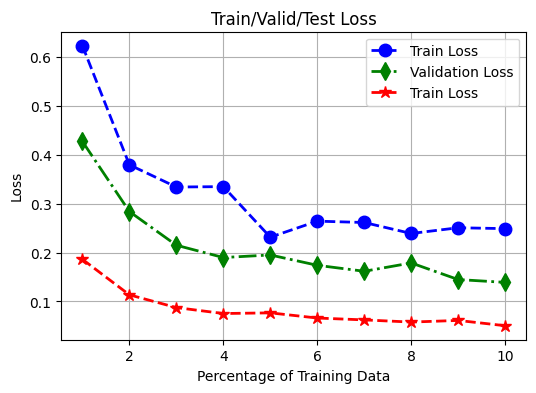

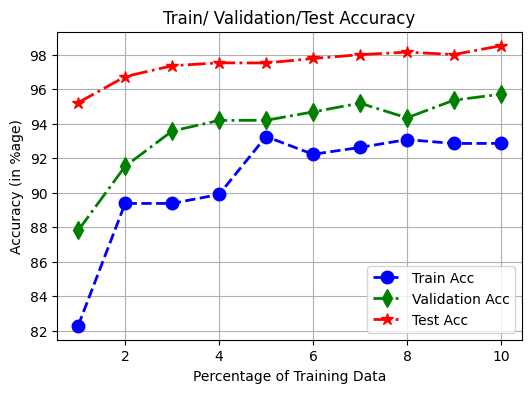

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6, 4))
plt.plot(perc_train_data, train_losses, color='blue', marker='o', linestyle='dashed',
     linewidth=2, markersize=9, label='Train Loss')
plt.plot(perc_train_data, val_losses, color='green', marker='d', linestyle='-.',
     linewidth=2, markersize=9, label='Validation Loss')
plt.plot(perc_train_data, test_losses, color='red', marker='*', linestyle='dashed',
     linewidth=2, markersize=9, label='Train Loss')
plt.xlabel('Percentage of Training Data')
plt.ylabel('Loss')
plt.title('Train/Valid/Test Loss')
plt.legend()
plt.grid()
plt.show()


plt.figure(figsize=(6, 4))
plt.plot(perc_train_data, train_accuracies, color='blue', marker='o', linestyle='dashed',
     linewidth=2, markersize=9, label='Train Acc')
plt.plot(perc_train_data, val_accuracies, color='green', marker='d', linestyle='-.',
     linewidth=2, markersize=9, label='Validation Acc')
plt.plot(perc_train_data, test_accuracies, color='red', marker='*', linestyle='-.',
     linewidth=2, markersize=9, label='Test Acc')
plt.xlabel('Percentage of Training Data')
plt.ylabel('Accuracy (in %age)')
plt.title('Train/ Validation/Test Accuracy')
plt.legend()
plt.grid()
plt.show()





